# 04 · Regions 1 and 2, structure in depth, and drift

**What this notebook shows.**
1. **Region 1** (filaments) is strongly anisotropic in the echo plane and
   changes as fast along W as along its most rapidly varying in-plane
   direction.
2. **Region 2** (a clump) is nearly isotropic in the plane.  Followed in a
   co-moving window, it changes more slowly along W than in the plane.
3. Across all 46 windows, how easily structure can be followed between the
   closely spaced epochs 2-4 tracks the **3D orientation** of the structure,
   not its in-plane isotropy.
4. Structure drifts in the same direction (toward -U) nearly everywhere.

All structure functions here are PSF-deconvolved in Fourier space (notebook
02, section 2): the noise is removed and the power spectrum divided by the
PSF transfer, capped at a gain of 20.  The result corresponds to an effective
resolution of ~0.011 ly instead of the PSF's 0.018 ly.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from mabsf import config as C, data as D, preprocess as P, regions as RG, shape as S, plotting
from mabsf.checks import check, targets

plotting.style()
RECOMPUTE = False      # True: recompute the per-window trackability / drift table (~2 min)
w = D.epoch_w()

## 1. Following Region 2 through depth

Each epoch of Region 2 is registered against epoch 1 by cross-correlation.
Epochs whose correlation peak exceeds 0.45 are "coherent"; a line through the
origin of their displacement against depth gives the drift (dU/dW, dV/dW).
The co-moving window is then centred at v (W_k - W_1) from the original
centre in each epoch.

Region 2 drift: dU/dW = -0.634, dV/dW = 0.177 (from 4 coherent epochs)


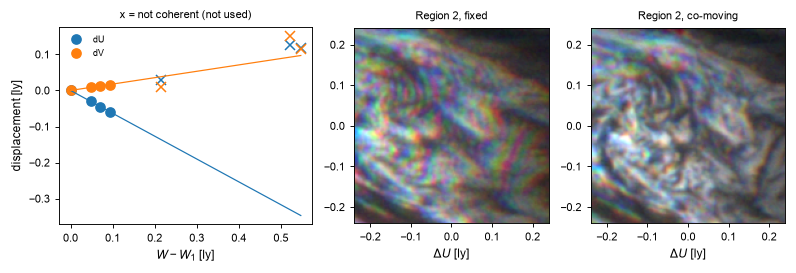

In [2]:
vu, vv, used = RG.fit_velocity(2)
cube2, _ = RG.region_cube(2)
rows = []
for k in range(7):
    dx, dy, cc = RG.global_shift(cube2[0], cube2[k])
    rows.append(dict(epoch=k + 1, dW=w[k] - w[0], dU=-dx * C.PIX_LY, dV=-dy * C.PIX_LY, peak_cc=cc, used=k in used))
reg = pd.DataFrame(rows)
print('Region 2 drift: dU/dW = %.3f, dV/dW = %.3f (from %d coherent epochs)' % (vu, vv, len(used)))
fig, axs = plt.subplots(1, 3, figsize=(plotting.W_IN, 2.5), gridspec_kw=dict(width_ratios=[1.3, 1, 1]))
a = axs[0]
for q, col in (('dU', 'C0'), ('dV', 'C1')):
    a.plot(reg.dW[reg.used], reg[q][reg.used], 'o', color=col, label=q)
    a.plot(reg.dW[~reg.used], reg[q][~reg.used], 'x', color=col)
x = np.linspace(0, w[-1] - w[0], 10)
a.plot(x, vu * x, 'C0-', lw=0.8); a.plot(x, vv * x, 'C1-', lw=0.8)
a.set_xlabel('$W - W_1$ [ly]'); a.set_ylabel('displacement [ly]'); a.legend(fontsize=6)
a.set_title('x = not coherent (not used)', fontsize=7)
cube2t, _ = RG.region_cube(2, (vu, vv))
ext = [-0.24, 0.24, -0.24, 0.24]
axs[1].imshow(plotting.rgb_composite(cube2), origin='lower', extent=ext); axs[1].set_title('Region 2, fixed', fontsize=7)
axs[2].imshow(plotting.rgb_composite(cube2t), origin='lower', extent=ext); axs[2].set_title('Region 2, co-moving', fontsize=7)
for a in axs[1:]:
    a.set_xlabel(r'$\Delta U$ [ly]')
fig.tight_layout()

In the fixed window the clump appears as offset red/green/blue copies; in
the co-moving window the three epochs line up and the clump looks grey.

## 2. In-plane and depth structure functions (panels B-E of the paper figure)

For each region, the deconvolved in-plane S2 is averaged in nine 20-deg
wedges of lag direction (lines, coloured by angle from +U).  The cross-epoch
S2 (points) measures the variation along W, at the depth separation of each
epoch pair (times sqrt(1 + |v|^2) in the co-moving window).

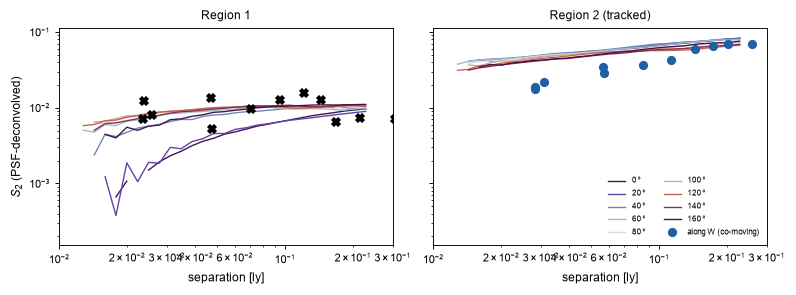

In [3]:
res = {1: RG.region_sf(1), 2: RG.region_sf(2, (vu, vv))}
cmap = plt.get_cmap('twilight_shifted')
fig, axs = plt.subplots(1, 2, figsize=(plotting.W_IN, 2.7), sharey=True)
for a, i in zip(axs, (1, 2)):
    R_ = res[i]
    for j, ang in enumerate(RG.ANGLES):
        a.loglog(R_['r'], R_['prof'][j], color=cmap((j + 0.5) / len(RG.ANGLES)), lw=0.9,
                 label='%d$^\\circ$' % ang)
    a.loglog(R_['w_sep'], R_['w_s2'], 'kX' if i == 1 else 'o', color='k' if i == 1 else '#1f5fa8', ms=5,
             label='along W' + (' (co-moving)' if i == 2 else ''))
    a.set_xlim(0.01, 0.3); a.set_xlabel('separation [ly]')
    a.set_title('Region %d' % i + (' (tracked)' if i == 2 else ''), fontsize=8)
axs[0].set_ylabel('$S_2$ (PSF-deconvolved)'); axs[1].legend(fontsize=5.5, ncol=2, loc='lower right')
fig.tight_layout()

## 3. The region claims (C1-C4)

In [4]:
rc = {i: RG.region_claims(res[i]) for i in (1, 2)}
pd.DataFrame(rc).rename(columns={1: 'Region 1', 2: 'Region 2 (tracked)'}).round(3)

,Region 1,Region 2 (tracked)
aniso_min,4.758,1.174
aniso_max,7.502,1.191
w_over_max_median,0.924,0.569
w_over_max_frac_0p5_1p5,0.909,0.600
w_over_mean_median,1.287,0.613
w_over_mean_min,0.646,0.386
n_w,11.000,10.000


* **C1, C2.**  Between 0.02 and 0.03 ly, the in-plane S2 differs between
  directions by a factor of **4.8-7.5 in Region 1**, but only **1.17-1.19 in
  Region 2**.
* **C3.**  In Region 1, the W points are a median 0.92 of the *largest*
  in-plane S2 at the same separation: the structure varies along W as fast as
  in its fastest in-plane direction.
* **C4.**  In Region 2, followed in its co-moving window, the W points are a
  median 0.61 (minimum 0.39) of the *mean* in-plane S2: the clump varies more
  slowly along W.

## 4. Trackability across the cloud (claims C5, C6)

For every window, the 0.01-0.1 ly structure maps of epochs 2, 3 and 4 (0.024-0.047
ly apart in W) are correlated pair by pair, at the best shift up to 12 px.
This is "how easily the eye can follow structure between epochs".  The noise
is negligible here (the noise-limited ceiling is ~0.99).

C5: epoch 2-4 correlation, Region 1 0.32, Region 2 0.86


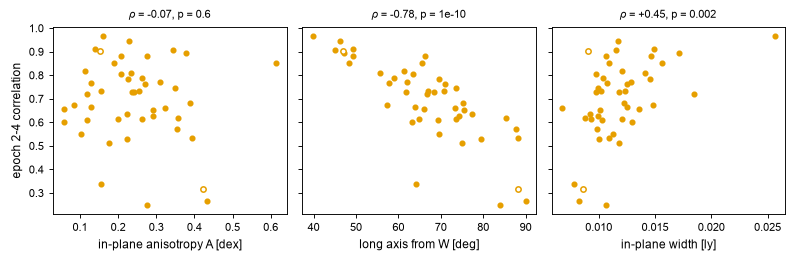

In [5]:
wins = P.sample_windows()
path = D.results('region_window_table.csv')
if RECOMPUTE or not os.path.exists(path):
    RG.window_table(wins).to_csv(path, index=False)
TW = pd.read_csv(path)
TW = TW.merge(S.window_table()[['row', 'col', 'incl', 'collapsed']], on=['row', 'col'])
c5 = {name: RG.trackability(*rc_) for name, rc_ in (('Region 1', S.R1_TILE), ('Region 2 box', RG.box_corner(2)))}
print('C5: epoch 2-4 correlation, Region 1 %.2f, Region 2 %.2f' % (c5['Region 1']['ncct'], c5['Region 2 box']['ncct']))
corr = {x: stats.spearmanr(TW[x], TW.ncct) for x in ('A', 'incl', 'l_min')}
fig, axs = plt.subplots(1, 3, figsize=(plotting.W_IN, 2.4), sharey=True)
for a, (x, lab) in zip(axs, (('A', 'in-plane anisotropy A [dex]'), ('incl', 'long axis from W [deg]'),
                              ('l_min', 'in-plane width [ly]'))):
    a.plot(TW[x][~TW.collapsed], TW.ncct[~TW.collapsed], 'o', ms=3, color=plotting.C_WIN)
    a.plot(TW[x][TW.collapsed], TW.ncct[TW.collapsed], 'o', ms=3.5, mfc='w', mec=plotting.C_WIN)
    a.set_xlabel(lab)
    a.set_title(r'$\rho$ = %+.2f, p = %.1g' % corr[x], fontsize=7)
axs[0].set_ylabel('epoch 2-4 correlation')
fig.tight_layout()

Trackability does **not** follow in-plane anisotropy (rho ~ -0.07).  It
follows the inclination of the 3D long axis strongly (rho ~ -0.78): structure
whose long axis tilts toward W persists from slice to slice.  (That
comparison is partly circular, since the inclination is fitted from the same
cross-epoch data.)  It also follows the in-plane width (rho ~ +0.45), which
is independent of the fit.  Regions 1 and 2 are near the two ends of the
trackability range.

## 5. Drift direction (claim D1)

For every window, the drift (dU/dW, dV/dW) on a 0.1 grid in [-2, 2] that best
aligns the epoch pairs 0.015-0.1 ly apart in depth.  The direction is robust;
the speed is not (along filaments the alignment is degenerate, and many
windows reach the grid edge).

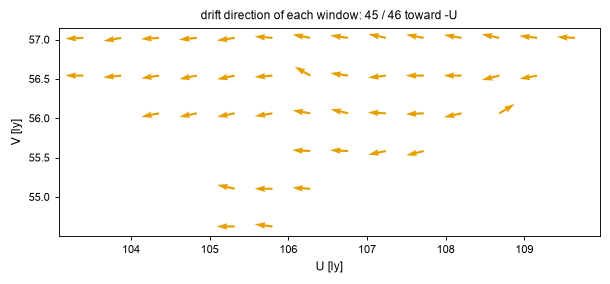

In [6]:
Ug, Vg = D.uv_grids()
fig, ax = plt.subplots(figsize=(plotting.W_IN, 2.6))
uc = np.array([Ug[0, c + 75] for c in TW.col]); vc = np.array([Vg[r + 75, 0] for r in TW.row])
mag = np.hypot(TW.vU, TW.vV)
ax.quiver(uc, vc, TW.vU / np.maximum(mag, 1e-9), TW.vV / np.maximum(mag, 1e-9), color=plotting.C_WIN,
          scale=30, width=0.004)
ax.set_aspect('equal'); ax.set_xlabel('U [ly]'); ax.set_ylabel('V [ly]')
n_minus = int((TW.vU < 0).sum())
ax.set_title('drift direction of each window: %d / %d toward -U' % (n_minus, len(TW)), fontsize=8)
fig.tight_layout()

## 6. Checks against the original analysis

In [7]:
T = targets(); A = np.load('../validation/targets_arrays.npz')
check('Region 2 drift (dU/dW, dV/dW)', [vu, vv], T['regions']['R2_velocity'], rtol=1e-12)
check('Region 2 coherent epochs', len(used), T['regions']['R2_n_coherent'], rtol=0)
for i in (1, 2):
    for k_, ka in (('prof', 'prof'), ('w_sep', 'wsep'), ('w_s2', 'ws2')):
        check('Region %d %s' % (i, k_), res[i][k_], A['R%d_%s' % (i, ka)], rtol=1e-10)
    for q in ('aniso_min', 'aniso_max', 'w_over_max_median', 'w_over_mean_median', 'w_over_mean_min'):
        check('Region %d %s' % (i, q), rc[i][q], T['region_claims']['R%d' % i][q], rtol=1e-10)
check('C5 trackability R1, R2 box', [c5['Region 1']['ncct'], c5['Region 2 box']['ncct']],
      [T['region_claims']['trackability_C5'][k]['ncct'] for k in ('R1', 'R2_fixed_box')], rtol=1e-10)
# the inclinations of the original analysis come from the stationary S2 estimator
TWs = pd.read_csv(path).merge(S.window_table(C.FIRST_SUBMISSION)[['row', 'col', 'incl']], on=['row', 'col'])
c6 = pd.read_csv('../validation/targets_c6.csv').merge(TWs, on=['row', 'col'], suffixes=('_t', ''))
for q in ('ncct', 'A', 'l_min', 'incl'):
    check('per-window %s' % q, c6[q].values, c6[q + '_t'].values, rtol=1e-8)
check('rho(trackability, inclination)', stats.spearmanr(TWs.incl, TWs.ncct)[0], T['trackability']['rho_ncct_incl'],
      rtol=1e-8)
check('rho(trackability, anisotropy)', corr['A'][0], T['trackability']['rho_ncct_A'], rtol=1e-8)
check('rho(trackability, width)', corr['l_min'][0], T['trackability']['rho_ncct_lmin'], rtol=1e-8)
check('windows drifting toward -U', n_minus, T['drift']['n_minus_U'], rtol=0)

ok   Region 2 drift (dU/dW, dV/dW)                    [-0.63388  0.17713]  (expected [-0.63388  0.17713])
ok   Region 2 coherent epochs                         4  (expected 4)
ok   Region 1 prof                                    [351 values, max |diff| 0]  (expected )
ok   Region 1 w_sep                                   [21 values, max |diff| 0]  (expected )
ok   Region 1 w_s2                                    [21 values, max |diff| 0]  (expected )
ok   Region 1 aniso_min                               4.75808  (expected 4.75808)
ok   Region 1 aniso_max                               7.50187  (expected 7.50187)
ok   Region 1 w_over_max_median                       0.923679  (expected 0.923679)
ok   Region 1 w_over_mean_median                      1.28669  (expected 1.28669)
ok   Region 1 w_over_mean_min                         0.645622  (expected 0.645622)
ok   Region 2 prof                                    [351 values, max |diff| 0]  (expected )
ok   Region 2 w_sep                 